In [1]:
# needed when using ssh connection (?)
#%pip install tensorboard
#%pip install numpy
#%pip install torch
#%pip install matplotlib
#%pip install os

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.utils.tensorboard import SummaryWriter

In [3]:
# TOGGLE/OPTIONS/HYPERPARAMETERS CELL
ssh_connected = 1 # change to 1 if connected to supercomputer

norm = 1 # change to 1 to normalise the fluxes
roll = 1 # change to 1 if wanting to roll the times/phases
noise_level = 0 # 0 for low noise level, 1 for high

early_stopping_toggle = 1 # 1: use early stopping
lr_scheduling_toggle = 1 # 1: use learning rate scheduling

num_params = 8 # number of parameters model will predict
B = batch_size = 10 # number of systems processed before forward passing
lr = 0.001
epochs = 1000

# early stop criteria:
patience = 15 # how many epochs in a row with no improvement there needs to be before it stops early
delta = 0.001 # the minimum performance increase to count as an improvement

# learning rate scheduling criteria:
factor_lr = 0.5 # the amount to reduce the learning rate by each time it is told to
patience_lr = 5 # how many epochs without improvement to wait before reducing lr
min_lr = 5e-5 # the lowest the learning rate is allowed to go

In [4]:
cwd = os.getcwd()


if ssh_connected == 0:
    num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
elif ssh_connected ==1:
    num_csvs = len(os.listdir("/home/astrouser/sean/Eclipsing Binaries/Data/ELISa lightcurve data"))


EB_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 
fluxes = np.array([])
phases = np.array([])
param_names = ["T_ratio", "T1", "q", "m1", "Omega1", "Omega2", "e", "i"]
    
T1 = []     # set empty lists for parameters
T_ratio = []
q = []
m1 = []
Omega1 = []
Omega2 = []
e = []
i = []

dist = []
period = []

params_1000 = {} # create empty dictionary for parameter list contianing 1000 values

for name in param_names: # loop through parameter names, adding their values to their name in the dictionary
        params_1000[name] = np.loadtxt(
            os.path.join(cwd, "Data", "ELISa synthetic parameters", f"{name}.csv"),
            delimiter=',',
            skiprows=0
        )

#2026-10-15: removing period as a target parameter and inputting it into system indstead, also inputting distance. these are features you would know from an observation
periods = np.loadtxt(os.path.join(cwd, "Data", "ELISa synthetic parameters", "period.csv"),delimiter=',',skiprows=0)
distances = np.loadtxt(os.path.join(cwd, "Data", "ELISa synthetic parameters", "distance.csv"), delimiter=',', skiprows=0)

params = {} # create empty dict for correct number of param values

for name in param_names:
    # give empty dictionary correct keys
        params[name]=[]

fluxes_dict={} # initalise dict for use with multiple passbands fluxes
fluxes_final={'Generic.Bessell.B','Generic.Bessell.V','Generic.Bessell.R','Generic.Bessell.I'}
log_mean_B = log_mean_V = log_mean_R = log_mean_I = []

# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(0, 4*num_csvs): # using 4 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        passbands = np.genfromtxt(data_path, delimiter=',', max_rows=1,dtype=str)[1:] # save all columns past 'time' as a list of strings


        phases = data[:, 0]

        label = EB_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)
        period.append(periods[i])
        dist.append(distances[i]) # select only the period and distance values with the correct indices to be used

        for name in param_names:
            # insert only the parameters of the systems that are used into the new one - so that the system number for parameters matches with fluxes.
            params[name].append(params_1000[name][i])


        for j, band in enumerate(passbands): # enumerate returns both the item itself and its index
            if band not in fluxes_dict: # initialise the dictionary if it doesnt exist
                fluxes_dict[band] = data[:,j+1] # j+1 is needed as data[0] is the times, lightcurve data begins in column [1]
            else:
                fluxes_dict[band] = np.vstack((fluxes_dict[band], data[:,j+1])) # add the data to the array within the dictionary as a new row

    else:
        continue
print(fluxes_dict['Generic.Bessell.R'].shape)

log_mean_B = np.append(log_mean_B, np.log10(fluxes_dict['Generic.Bessell.B'].mean(axis=1))) # finds the mean flux of each passband to be used as an input
log_mean_V = np.append(log_mean_V, np.log10(fluxes_dict['Generic.Bessell.V'].mean(axis=1)))
log_mean_R = np.append(log_mean_R, np.log10(fluxes_dict['Generic.Bessell.R'].mean(axis=1)))
log_mean_I = np.append(log_mean_I, np.log10(fluxes_dict['Generic.Bessell.I'].mean(axis=1)))

(1200, 100)


In [5]:
print(params.keys())

dict_keys(['T_ratio', 'T1', 'q', 'm1', 'Omega1', 'Omega2', 'e', 'i'])


In [6]:
# creating phase offset parameter, intended to model the synthetic data more as realistic data, and to be predicted as a parameter in itself
print(fluxes_dict['Generic.Bessell.B'].shape)

system_length = fluxes_dict['Generic.Bessell.B'].shape[1] # how any data points are in each system

# at the moment, each phases_array is a 2d array, with 1000 rows (one for each system), each with 100 data points. 
# these data points are always 0.00 to 0.99, increasing by 0.01, for a totla of 100 data points.
# the goal of offsetting the phases is to make the data more like realistic observations,
# where the eclipse minimum does not always occur at exactly the same phase, as is happening here.

# the goal: add an offset to the phases. however, the range of phases should still be 0-0.99

# NOTE: rolling must occur during training, randomly per epoch
# otherwise the model will just learn the shapes and exact locations of the curves, instead of figuring out the phase shift and parameters
# so: define helper function to use later:
# side note: this means it is easier to predict the phase offset as an additional loss, instead of as an extra parameter
    # because parameters are loaded and initialised much earlier on in the program than the training where offset is added, it is easier to treat them separately

def random_roll(x, shifts=None):
    # x: (B,(W), L) tensor. rolls each curve by its own shift using np.roll
    B, W, L = x.shape # with 4 passbands: shape is (1200, 4, 100)
    if shifts is None:
        shifts = np.random.randint(0, L, B)
    x_np = x.detach().cpu().numpy()
    rolled = np.stack([np.roll(row, -s, axis=-1) for row, s in zip(x_np, shifts)])
    # returns the input tensor but rolled, and the shifts used for each batch (size B)
    return torch.tensor(rolled, dtype=torch.float32, device=x.device), shifts

print(np.random.randint(0,system_length,10))

def offset_target(s, L=system_length):
    # treating phases as an angle temporarily, to allow MSE to work with circular data
    # an offset of 0 and 99 are very close to each other here, but MSE would read them as very far apart.
    # this fixes that by predicting the cos and sin of offset/100

    angle = 2 * np.pi * torch.as_tensor(s).float() / L
    return torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)


(1200, 100)
[42 61 94 14 63 57 64 37 37 94]


In [7]:
# sanity check cell
for band in passbands:
    print(fluxes_dict[band].shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(len(params['T_ratio']))

(1200, 100)
(1200, 100)
(1200, 100)
(1200, 100)
1201
(1200,)
1200


In [8]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cuda


In [9]:

fluxes_normed = {}
flux_std = {} # save std of fluxes for use in noise calculations later

if norm == 1:
    for band in passbands:
        fluxes_normed[band] = fluxes_dict[band] / fluxes_dict[band].mean(axis=1, keepdims=True) - 1.0
        flux_std[band] = fluxes_normed[band].std() # saving stds
        fluxes_normed[band] = fluxes_normed[band] / flux_std[band]

        flux_std_t = torch.tensor([flux_std[band]],dtype=torch.float32, device=device) # converting flux_std to a tensor

    band_B_tensor = torch.tensor(fluxes_normed['Generic.Bessell.B'], dtype=torch.float32)
    band_V_tensor = torch.tensor(fluxes_normed['Generic.Bessell.V'], dtype=torch.float32)
    band_R_tensor = torch.tensor(fluxes_normed['Generic.Bessell.R'], dtype=torch.float32)
    band_I_tensor = torch.tensor(fluxes_normed['Generic.Bessell.I'], dtype=torch.float32)
    combined_tensor = torch.stack([band_B_tensor, band_V_tensor, band_R_tensor, band_I_tensor],dim=1)

    log_B_tensor = torch.tensor(log_mean_B,dtype=torch.float32)
    log_V_tensor = torch.tensor(log_mean_V,dtype=torch.float32)
    log_R_tensor = torch.tensor(log_mean_R,dtype=torch.float32)
    log_I_tensor = torch.tensor(log_mean_I,dtype=torch.float32)
    combined_log_tensor = torch.stack([log_B_tensor,log_V_tensor,log_R_tensor,log_I_tensor],dim=1)

    light_curve_labels = torch.tensor(labels, dtype=torch.long)

elif norm == 0:
    band_B_tensor = torch.tensor(fluxes_dict['Generic.Bessell.B'], dtype=torch.float32)
    band_V_tensor = torch.tensor(fluxes_dict['Generic.Bessell.V'], dtype=torch.float32)
    band_R_tensor = torch.tensor(fluxes_dict['Generic.Bessell.R'], dtype=torch.float32)
    band_I_tensor = torch.tensor(fluxes_dict['Generic.Bessell.I'], dtype=torch.float32)
    light_curve_labels = torch.tensor(labels, dtype=torch.long)

params_tensor = torch.tensor(
    # stack parameters into one tensor with shape (N, 8), with N: the system number, and the 8 being each parameteer value for that system
    np.stack([params[name] for name in param_names], axis=1), dtype=torch.float32)

period_tensor = torch.tensor(period, dtype=torch.float32) # converting list of periods into a tensor to be inputted
dist_tensor = torch.tensor(dist, dtype=torch.float32) # same for distance


print(params_tensor.shape)
print(combined_tensor.shape)
print(combined_log_tensor.shape)
print(log_B_tensor.shape)
print(period_tensor.shape)
print(dist_tensor.shape)

torch.Size([1200, 8])
torch.Size([1200, 4, 100])
torch.Size([1200, 4])
torch.Size([1200])
torch.Size([1200])
torch.Size([1200])


In [10]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_dict['Generic.Bessell.B'].shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_dict['Generic.Bessell.B'].shape[0])

full_dataset = TensorDataset(combined_tensor, combined_log_tensor, light_curve_labels, params_tensor, period_tensor, dist_tensor)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_params = params_tensor[train_dataset.indices]
p_mean = train_params.mean(dim=0).to(device) # mean of each parameter. a tensor of shape (9)
p_std = train_params.std(dim=0).to(device) # std of each parameter. these will be used to normalise the parameters later

# Loading training and validation data into DataLoader for batching
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()  # Initialize TensorBoard writer

In [11]:
# helper function to be able to pass the scalar inputs into the model! (the average log flux of each passband)

print(combined_log_tensor[train_dataset.indices].shape)
print(period_tensor[train_dataset.indices].shape)
print(len(train_dataset.indices))

def make_scalars(L):               # L: (N,4) log10 mean flux for B,V,R,I
    return torch.stack([L[:,1],            # V band
                        L[:,0]-L[:,1],     # B-V colour
                        L[:,1]-L[:,2],     # V-R
                        L[:,2]-L[:,3]],     # R-I 
                       dim=1)

train_scalars = make_scalars(combined_log_tensor[train_dataset.indices])
scalar_mean = train_scalars.mean(0).to(device)
scalar_std  = train_scalars.std(0).to(device)


period_mean, period_std = period_tensor.mean().to(device), period_tensor.std().to(device)

dist_mean, dist_std = dist_tensor.mean().to(device), dist_tensor.std().to(device)

def build_scalars(log_fluxes, periods, inclinations):
    s = (make_scalars(log_fluxes.cpu()).to(device) - scalar_mean) / scalar_std  # (B, 4)
    p = ((periods.to(device) - period_mean) / period_std ).unsqueeze(1) # (B, 1). Unsqueeze turns it from just (B,) to (B, 1) so it can be concatenated below
    d = ((dist.to(device) - dist_mean) / dist_std).unsqueeze(1) # (B, 1)
    return torch.cat([s,p,d],dim=1) # (B, 6)

torch.Size([960, 4])
torch.Size([960])
960


In [12]:
# function to add noise to flux inputs
if noise_level == 0:
    low=0.001
    high=0.01
elif noise_level ==1:
    low=0.005
    high=0.05

def add_noise(inputs):
    #inputs: (B, 4, L), exactly the same as inputs for the model
    #sigma_range: the range (percentage) of noise level added to each point
    batch = inputs.shape[0]
    sigma = torch.exp(torch.empty(B,1,1, device=inputs.device).uniform_(np.log(low),np.log(high))) 
    # low and high are the lower and upper bounds of sigma
    # sigma is the percentage amount of noise to be added to each system.
        # it is log-drawn to allow equal drawings of possible values
        # e.g. non log drawing with a range of 0.001 to 0.01, the vast majority will be above 0.002-ish.
        # log-drawn prevents uniform drawing from being dominated by higher end values
    noise = torch.randn(inputs.shape, device=inputs.device) # returns a tensor containing a randomly pulled values from a normal distribution with mean 0 and std 1, of size inputs.shape
    return inputs + sigma * noise / flux_std_t # dividing by std of normalised fluxes makes sigma now a true fraction of the flux value

In [13]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [14]:
# simplified cnn, not resnet:
def length(length, kernel_size, stride):
    return ((length - kernel_size) // stride) + 1

class CNN(nn.Module):
    def __init__(self, n_classes=2, n_params=num_params, seq_len=system_length):
        super(CNN, self).__init__() 
        # circular padding mode informs to model that curves are periodic, i.e. treat phase 0.99 as a neighbour to 0.00, not furthest away possible

        self.conv1 = nn.Conv1d(in_channels=4, out_channels=32, kernel_size=7, padding=3, padding_mode='circular') 
        self.pool = nn.AvgPool1d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=5, padding=2, padding_mode='circular')
        self.conv3 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, padding=2, padding_mode='circular')
        self.conv4 = nn.Conv1d(in_channels=128, out_channels=128, kernel_size=5, padding=2, padding_mode='circular') 

        self.sharedfc = nn.Sequential(nn.Linear(256 + 6, 128),nn.ReLU()) # shared output node for two outputs (+6 exists for the scalars)
        self.sharedfc2 = nn.Linear(128,128,nn.ReLU()) # 2nd layer for the scalar values to allow more depth in comparing input values
        self.cls_head = nn.Linear(128, n_classes) # output head for classification (detached vs overcontact)
        self.rgs_head = nn.Linear(128, n_params) # output head for parameters (regression)
        self.offset_head = nn.Sequential(nn.Flatten(), 
                                         nn.Linear(128 * (system_length // 4), 64), nn.ReLU(), nn.Linear(64,2)) # separate outpt head for the offset.

# cnn conv layer length formula: ((length - kernel_size + 2*padding) / stride){rounded down} + 1
# size: (batch_size, channels, length)



    def forward(self, x, s): # input size: (batch_size, 500)
        # unsqueeze(1) no longer needed as it converted (B, 500) into (B, 1, 500) (1 in_channel), but we now already have (B, 4, 500), so the extra dimension isn't needed
        x = F.relu(self.conv1(x))   # (B, 32, 500)
        x = F.relu(self.conv2(x))   # (B, 64, 500)
        x = self.pool(x)            # (B, 64, 250)
        x = F.relu(self.conv3(x))   # (B, 128, 250)
        x = self.pool(x)            # (B, 128, 125)
        x = F.relu(self.conv4(x))   # (B, 128, 125)
        pooled = torch.cat([x.mean(dim=2), x.amax(dim=2), s], dim=1) # pools data together to lose position data. size 128 * 2
        # pooled is important for the parameters, so that the model doesn't just learn the positions. phase offset, however, needs the positions.
        y = self.sharedfc(pooled) # sharedfc would lose valuable position data, which is needed for the offset, but not the other two.
        y = self.sharedfc2(y)
        return self.cls_head(y), self.rgs_head(y), self.offset_head(x) # three outputs. first two receive pooled data, without positions.

In [15]:
best_val_loss = float("inf") # initialising the first best loss as infinity
no_improvement_count = 0 # initialising iterating counter

class EarlyStopping:
    def __init__(self, patience=10, delta=0.01, verbose=False):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.best_loss = None
        self.no_improvement_count = 0
        self.stop_training = False

    def check_early_stop(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1
            if self.no_improvement_count >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print(f"Stop early due to no improvement")

# now initialise it:
early_stopping = EarlyStopping(patience=patience, delta=delta, verbose=True)


In [16]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
if lr_scheduling_toggle==1:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min',factor=factor_lr,patience=patience_lr,min_lr=min_lr)
C_criterion = nn.CrossEntropyLoss() # classification criterion
R_criterion = nn.MSELoss() # regression criterion
offset_criterion = nn.MSELoss() # offset criterion, on cos and sin of offset as angle


W_rgs = 1.0 # weighting of regression task against classification
W_off = 1.0 # weighting of offset against other two losses

# validation shifts are drawn ONCE, so validation numbers are comparable between epochs:
    # validation fluxes are not rolled each epoch and batch like training
val_shifts = np.random.randint(0, system_length, (len(val_dataset)))

loss, val_loss, val_accuracy = [], [], []
train_losses, val_losses, val_C_accuracies, val_R_accuracies,offset_losses = [], [], [], [], []

param_mse_array, param_mae_array = np.zeros((0,num_params)),np.zeros((0,num_params)) # initialising empty arrays to store parameter errors later

train_C_losses, train_R_losses, train_offset_losses = [], [], []
val_C_losses, val_R_losses, val_offset_losses = [], [], []
offset_errs = []
for epoch in range(epochs):
    val_accuracy = 0
    model.train()
    train_loss=0    
    train_C_loss, train_R_loss, train_offset_loss = 0,0,0
    # initialise tensors to store individual parameter losses:
    R_squared_errors = torch.zeros(num_params, device=device)
    R_absolute_errors = torch.zeros(num_params, device=device)
    for inputs, log_mean_fluxes, cls_labels, param_targets, periods, dist in train_loader:

        inputs = add_noise(inputs.to(device))  # Move inputs to the same device as the model and add noise
        scalars = build_scalars(log_mean_fluxes,periods,dist) # allow input for and normalise the scalar inputs
        cls_labels = cls_labels.to(device)
        param_targets = (param_targets.to(device) - p_mean) / p_std # normalising! as otherwise it would be dominated by high parameters e.g. temperature


        if roll == 1:
            inputs, s = random_roll(inputs) # gives a fresh offset to each curve every batch and every epoch
            off_target = offset_target(s).to(device) # transforms into cos and sin of offset as angle, to allow circular reading

        optimizer.zero_grad() # set gradients to zero
        cls_out, rgs_out, offset_out = model(inputs, scalars) # forward pass outputs
        C_loss = C_criterion(cls_out, cls_labels) # calculate loss for classification based on predictions and true labels
        R_loss = R_criterion(rgs_out, param_targets) # loss for regression taks, based on predictions and (normalised) param labels
        if roll == 1:
            offset_loss = offset_criterion(offset_out, off_target) # loss for phase offset


        train_C_loss += C_loss.item() # logging individual losses
        train_R_loss += R_loss.item()
        if roll == 1:
            train_offset_loss += offset_loss.item()
            loss = C_loss + W_rgs * R_loss + W_off * offset_loss # combine losses into one, with weight depending on W_rgs and W_off
        elif roll == 0:
            loss = C_loss + W_rgs * R_loss # loss not including offset loss

        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() # accumulate loss for the epoch
       
    train_losses.append(train_loss / len(train_loader))
    train_C_losses.append(train_C_loss / len(train_loader))
    train_R_losses.append(train_R_loss / len(train_loader))
    if roll ==1:
        train_offset_losses.append(train_offset_loss / len(train_loader))
    writer.add_scalar('Training Loss', train_losses[-1], epoch)

# Validation
    model.eval()
    val_loss, C_correct, R_correct =0,0,0
    val_C_loss = val_R_loss = val_offset_loss = 0.0
    abs_err = torch.zeros(len(param_names),device=device) # create empty tensor of size (num_params)
    val_start = 0 # initialising indexing for random_roll

    with torch.no_grad(): # make sure the gradients changed in this step
        for inputs, log_mean_fluxes, cls_labels, param_targets, periods, dist in val_loader:
            inputs = add_noise(inputs.to(device))  # Move inputs to the same device as the model, and add noise
            scalars = (build_scalars(log_mean_fluxes,periods,dist)) # allow input for and normalise the scalar inputs
            cls_labels = cls_labels.to(device)
            param_true = param_targets.to(device) # save the true parameters
            param_norm = (param_true - p_mean) / p_std # save the normalised parameters

            

            if roll == 1:
                shifts = val_shifts[val_start:val_start+B] # each shift applied to the fluxes should be correctly indexed
                inputs, _ = random_roll(inputs,shifts)
                val_start += B # iterate 
                off_target = offset_target(shifts).to(device) # convert into cos and sin again

            cls_out, rgs_out, offset_out = model(inputs,scalars)


            # Individual parameter squared and absolute errors. tensor of size (num_params) for each epoch, one for each parameter.
            param_mse = ((rgs_out - param_norm) ** 2).mean(dim=0)
            param_mae = torch.abs(rgs_out - param_norm).mean(dim=0)

            R_squared_errors += param_mse * rgs_out.size(0) # totals up the squared errors for each parameter
            R_absolute_errors += param_mae * rgs_out.size(0) # totals up absolute errors for each parameter. 
            # both above lines are then multiplied by the batch size to get the total error for each parameter across the entire validation set.
            val_N = len(val_loader.dataset)
            val_C_loss += ((C_criterion(cls_out, cls_labels)).item() * B) / val_N
            val_R_loss += ((R_criterion(rgs_out, param_norm)).item() * B) / val_N
            if roll == 1:
                val_offset_loss += ((offset_criterion(offset_out, off_target)).item() * B) / val_N
                val_loss = (val_C_loss + W_rgs * val_R_loss + W_off * val_offset_loss)
            elif roll ==0:
                val_loss = (val_C_loss + W_rgs * val_R_loss)



            C_correct += (cls_out.argmax(dim=1) == cls_labels).sum().item()
            R_correct += torch.abs(rgs_out - param_norm).sum().item()



    val_losses.append(val_loss)
    val_C_accuracies.append(C_correct / val_N)
    val_R_accuracies.append(R_correct / (val_N * rgs_out.shape[1]))

    if lr_scheduling_toggle ==1:
        scheduler.step(val_losses[-1])


    val_C_losses.append(val_C_loss)
    val_R_losses.append(val_R_loss)
    if roll ==1:
        val_offset_losses.append(val_offset_loss)
    writer.add_scalar('Validation Loss', val_losses[-1], epoch)

    param_mse = R_squared_errors / len(val_loader.dataset)
    param_mae = R_absolute_errors / len(val_loader.dataset)

    # collect parameter errors for plotting later:
    param_mse_array = np.vstack([param_mse_array, param_mse.cpu().numpy()])
    param_mae_array = np.vstack([param_mae_array, param_mae.cpu().numpy()])

    for name, mse, mae in zip(param_names, param_mse, param_mae):
        print(f"{name:8s} MSE={mse.item():.4f}, MAE={mae.item():.4f}")


    if early_stopping_toggle == 1:
        # check for early stopping:
        early_stopping.check_early_stop(val_losses[-1])

        if early_stopping.stop_training:
            print(f"Early stopping triggered at epoch {epoch}.")
            break

    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}")
    print(f"  train C_loss {train_C_loss/len(train_loader):.4f}, R_loss {train_R_loss/len(train_loader):.4f},Val Acc (Classification): {val_C_accuracies[-1]:.4f}, Val MAE (Parameters): {val_R_accuracies[-1]:.4f}")

T_ratio  MSE=0.6323, MAE=0.6498
T1       MSE=0.2887, MAE=0.4626
q        MSE=0.7869, MAE=0.7361
m1       MSE=1.0209, MAE=0.8693
Omega1   MSE=0.8410, MAE=0.7456
Omega2   MSE=0.9679, MAE=0.8122
e        MSE=0.4455, MAE=0.4881
i        MSE=0.8320, MAE=0.7712
Epoch 0: Training Loss: 1.3024, Validation Loss: 1.0492
  train C_loss 0.2707, R_loss 0.7718,Val Acc (Classification): 0.9875, Val MAE (Parameters): 0.6919
T_ratio  MSE=0.4428, MAE=0.4791
T1       MSE=0.1944, MAE=0.3649
q        MSE=0.7557, MAE=0.7014
m1       MSE=0.9156, MAE=0.8285
Omega1   MSE=0.8052, MAE=0.7391
Omega2   MSE=0.9418, MAE=0.7980
e        MSE=0.3668, MAE=0.4250
i        MSE=0.7227, MAE=0.7152
Epoch 1: Training Loss: 0.9538, Validation Loss: 0.9031
  train C_loss 0.1072, R_loss 0.6514,Val Acc (Classification): 0.9792, Val MAE (Parameters): 0.6314
T_ratio  MSE=0.3622, MAE=0.4297
T1       MSE=0.0936, MAE=0.2458
q        MSE=0.7670, MAE=0.6982
m1       MSE=0.9157, MAE=0.8141
Omega1   MSE=0.8353, MAE=0.7452
Omega2   MSE=0.9

In [17]:
# todo plot accuracy - done
# make parameters independent in elisa(m2, T2) - done
# include parameters in network¨
    # correct output neurons - done
    # update data loaders - done
    # 2 loss functions - one for classification (have now), one for regression (MSE) for parameters - done
    # then combine losses - done
    # make the model actually able to predict all parameters - all but T_ratio, period and m1
# begin to add noise, and phase offset (custom dataloader,), predict phase offset as new parameter 
    # add phase offset and predict it - done
    # move phase offset to occur per epoch, so that model cannot just memorise the curve patterns - done
    # add noise to flux inputs, perhaps include a low and high noise level and compare
    # re-run elisa, this time collecting inclination and distance as parameters to predict/input respectively

# the model really doesn't want to learn m1 or the period
    # fix this?
    # or remove them as targets?
    # generate more ELISa data? like 10 times the amount and leave running overnight?
    # period could be because the time units are simply the phase separated into 100 points, nothing there relates to physical units

# click <> in bottom left, click ssh, type ssh astrouser@130.238.192.91, password is astro26
# note: files will not transfer to remote server
# WinSCP - use to copy and paste files between this laptop and remote server

# people who might want ml 
# Anish (if these fail, ask Anish for suggestions) - sent, helpful reply
    # if nothing soon, send to Oleg and Nikolai too
# Ulrike - sent, no reply
# Ishaan Kothiyal (phd student) - sent, no reply
# IRF (space physics department)
    # Inaki, Atlas - ?
# ai4physics seminar 

In [18]:
print(val_losses)

[1.04918868575866, 0.9030958646908402, 0.8382729726654361, 0.7435001709745847, 0.6875584855006309, 0.6387160614176537, 0.6087824495637808, 0.5908709427149006, 0.5334097290154508, 0.5503253984349309, 0.5395881302053265, 0.47752802967018704, 0.504804119829411, 0.49303724984141195, 0.48740635034118907, 0.4300231051517282, 0.4639580362835052, 0.43638836813321774, 0.4373497885250496, 0.4509159404099895, 0.4376620595212444, 0.4038938213627716, 0.39362748545136134, 0.37275880150142865, 0.3529380514105469, 0.36292407932508775, 0.3811392449495467, 0.38526054687550493, 0.3464718227734238, 0.3476269301009628, 0.3307562711909972, 0.3373233502402684, 0.31460340268070774, 0.36093528494454097, 0.31363694225740346, 0.3069329689065702, 0.30219916602508573, 0.2968829029555309, 0.3973872851176831, 0.30382055997430757, 0.29731393639002585, 0.37856838904534135, 0.30510388217457296, 0.2934488742357644, 0.26915937563126136, 0.27848144252538987, 0.2696115506257684, 0.24723162862471781, 0.3038800509070445, 0.2

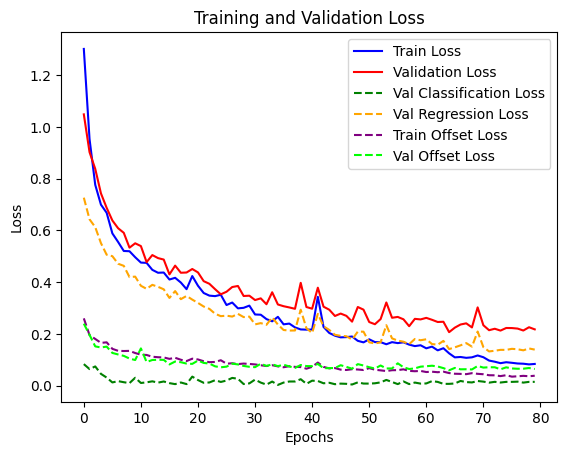

In [19]:
# Plot training/validation loss
plt.figure()
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.plot(val_C_losses, label='Val Classification Loss', color='green',linestyle='dashed')
plt.plot(val_R_losses, label='Val Regression Loss', color='orange',linestyle='dashed')
if roll == 1:
    plt.plot(train_offset_losses, label="Train Offset Loss", color='purple',linestyle='dashed')
    plt.plot(val_offset_losses, label='Val Offset Loss',color='lime',linestyle='dashed')


#plt.plot(val_C_accuracies, label="Validation Classification Accuracy", color="green")
#plt.plot(val_R_accuracies, label="Validation Regression Accuracy", color='orange')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [20]:
# Note: an MSE of 1 means it will always predict the mean, which means the MSE will equal the varience of the parameter (1 for normalised parameters).

(80, 8)
['T_ratio', 'T1', 'q', 'm1', 'Omega1', 'Omega2', 'e', 'i']


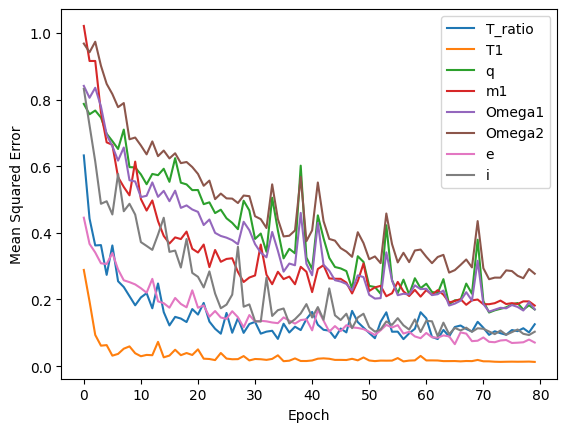

In [21]:
# plotting individual parameter mean squared errors
print(param_mse_array.shape)
print(param_names)

plt.figure()
for i in range(param_mse_array.shape[1]):
    plt.plot(range(param_mse_array.shape[0]), param_mse_array[:,i],label=param_names[i])

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()

(80, 8)
['T_ratio', 'T1', 'q', 'm1', 'Omega1', 'Omega2', 'e', 'i']


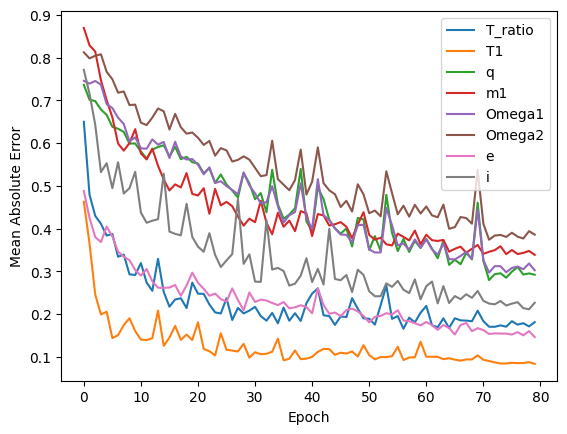

In [22]:
# plotting individual parameter mean absolute errors
print(param_mae_array.shape)
print(param_names)

plt.figure()
for i in range(param_mae_array.shape[1]):
    plt.plot(range(param_mae_array.shape[0]), param_mae_array[:,i],label=param_names[i])
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()

(1200, 100)


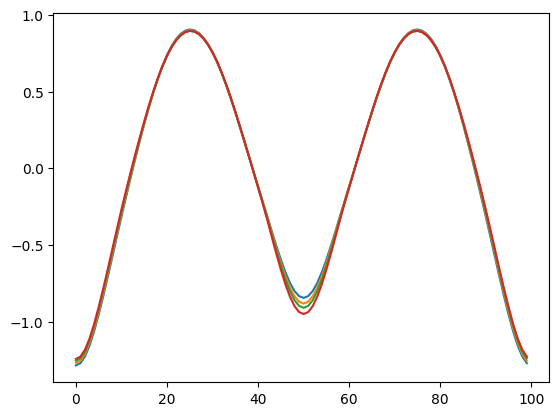

In [23]:
print(fluxes_normed['Generic.Bessell.B'].shape)


for band in passbands:
    plt.plot(fluxes_normed[band][12])